In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

df = pd.read_csv('data_jobs.csv')

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

<Axes: xlabel='job_title_short'>

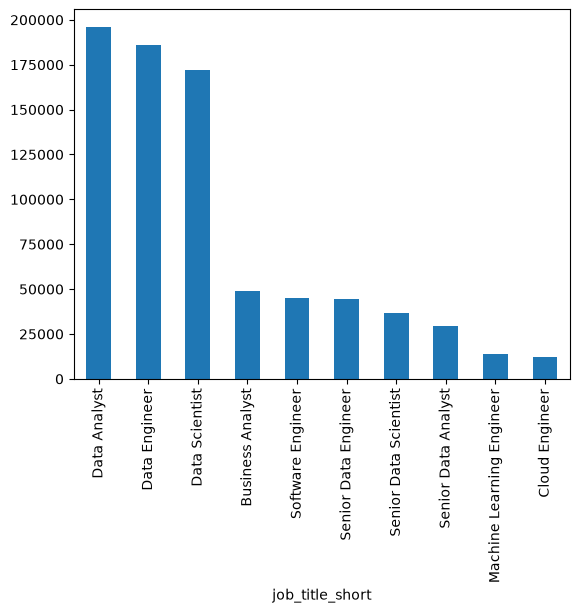

In [ ]:
df['job_title_short'].value_counts().plot(kind='bar')

In [7]:
df['job_schedule_type'].value_counts().head(3)

job_schedule_type
Full-time     701727
Contractor     34793
Internship      8742
Name: count, dtype: int64

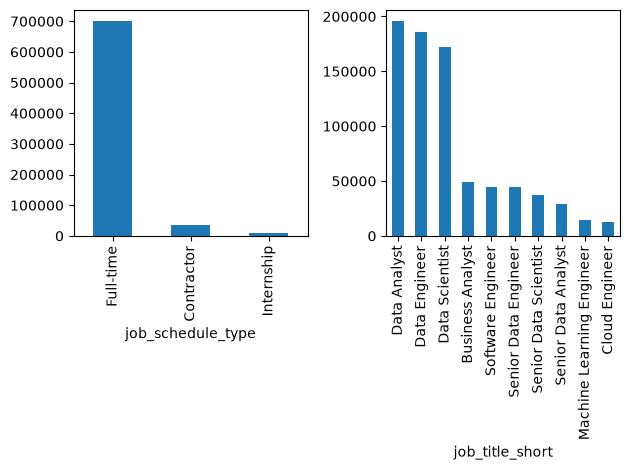

In [13]:
fig, ax = plt.subplots(1, 2)

df['job_title_short'].value_counts().plot(kind='bar', ax=ax[1])
df['job_schedule_type'].value_counts().head(3).plot(kind='bar', ax=ax[0])

fig.tight_layout()

In [14]:
df_skills = df.copy()
df_skills = df_skills.explode('job_skills')
skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()
df_skills_count = skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

df_skills_count

,job_skills,job_title_short,skill_count
1480,python,Data Scientist,113711
1822,sql,Data Engineer,113130
1479,python,Data Engineer,108022
1821,sql,Data Analyst,92428
1823,sql,Data Scientist,78982
...,...,...,...
2173,webex,Senior Data Scientist,1
293,codecommit,Business Analyst,1
2233,xamarin,Machine Learning Engineer,1
1087,mlr,Machine Learning Engineer,1


In [16]:
job_titles = ['Data Scientist', 'Data Engineer', 'Data Analyst']

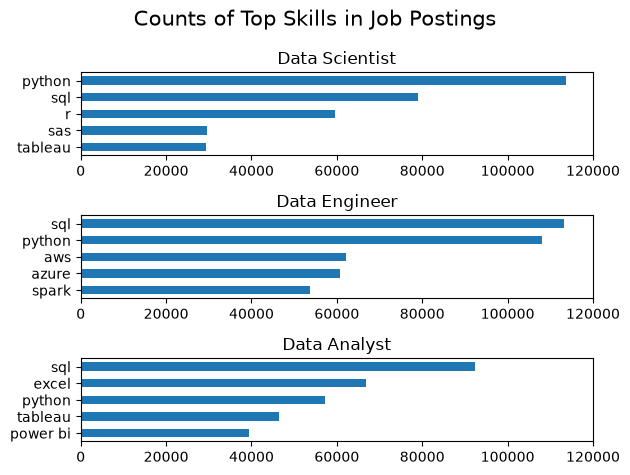

In [34]:
fig, ax = plt.subplots(3, 1)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head()
    df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0, 120000)

fig.suptitle('Counts of Top Skills in Job Postings', fontsize=15)
fig.tight_layout()

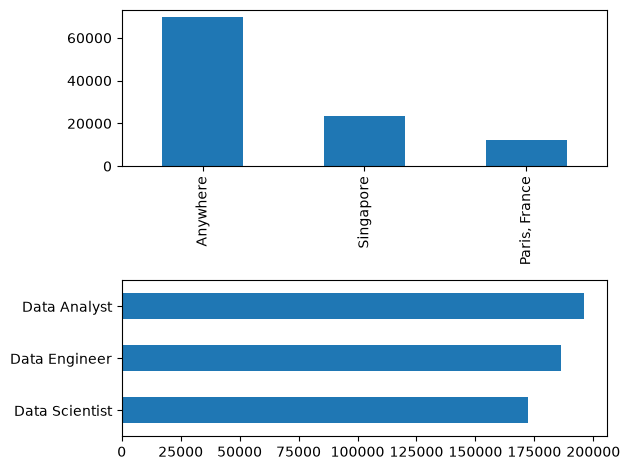

In [45]:
fig, ax = plt.subplots(2,1)
df.groupby('job_location').size().sort_values(ascending=False).head(3).plot(kind='bar', ax=ax[0])
df.groupby('job_title_short').size().sort_values(ascending=False).head(3).plot(kind='barh', ax=ax[1])
ax[1].invert_yaxis()
ax[0].set_xlabel('')
ax[1].set_ylabel('')
fig.tight_layout()

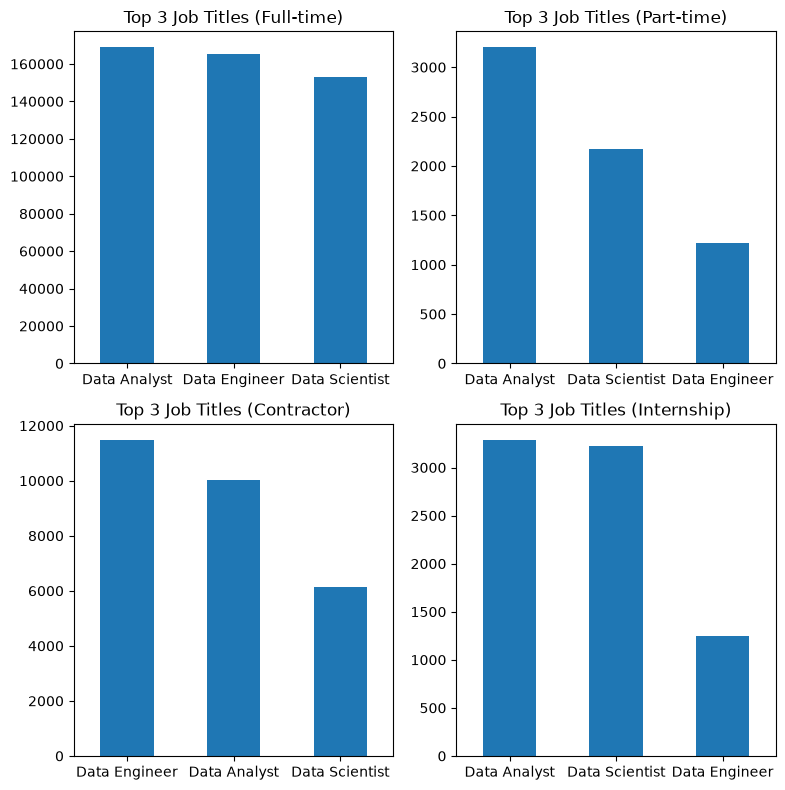

In [52]:
fig, ax = plt.subplots(2,2, figsize=(8, 8))
ax = ax.flatten()
schedules = ['Full-time', 'Part-time', 'Contractor', 'Internship']

for i, schedule in enumerate(schedules):
    df_plot = (df[df['job_schedule_type'] == schedule]
               .copy()
               .groupby('job_title_short')
               .size()
               .sort_values(ascending=False)
               .head(3))
    df_plot.plot(kind='bar', ax=ax[i], title=f'Top 3 Job Titles ({schedule})', rot=0)
    ax[i].set_xlabel('')


fig.tight_layout()

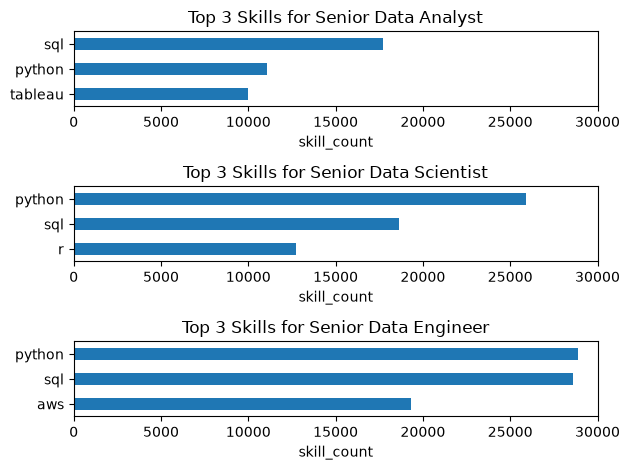

In [54]:
fig, ax = plt.subplots(3,1)
job_roles = ['Senior Data Analyst', 'Senior Data Scientist', 'Senior Data Engineer']

for i, job_role in enumerate(job_roles):
    df_plot = df[df['job_title_short'] == job_role].copy().explode('job_skills')
    df_plot.groupby('job_skills').size().sort_values(ascending=False).head(3).plot(kind='barh', ax=ax[i], title=f'Top 3 Skills for {job_role}')
    ax[i].invert_yaxis()
    ax[i].set_xlim(0,30000)
    ax[i].set_xlabel('skill_count')
    ax[i].set_ylabel('')

fig.tight_layout()